# Detección de patrones de riesgo sobre la salida del Explicador de Riesgo

Este notebook toma la salida del **Explicador de Riesgo** (módulo de explicabilidad de
Retention Partner) y busca **patrones de comportamiento riesgoso** entre las matrículas
de riesgo Alto y Medio: qué causas se repiten, en qué contextos se concentran y qué
combinaciones de hechos aparecen juntas.

La materia prima es la columna `full_facts`: la base auditable con los tres hechos de
mayor peso SHAP por matrícula (variable, valor, severidad relativa a sus pares, macro
y dirección de riesgo). El diccionario `var_definitions.json` aporta la descripción,
dimensión e interpretación de cada variable.

**Estructura del análisis**

| Nivel | Qué hace | Salida |
|---|---|---|
| 0 | Carga, anonimización, parseo de `full_facts`, control del diccionario | `hechos` (tabla larga) |
| 1 | Panorama: causas dominantes, perfiles, severidad; riesgo relativo por contexto | figuras 01–03 |
| 2 | **Arquetipos deterministas**: `contexto × perfil_riesgo × hecho dominante` | `arquetipos.csv` |
| 3 | **Hallazgos sistémicos**: contextos donde una misma causa supera el umbral de concentración | `hallazgos_sistemicos.csv` |
| 4 | **Co-ocurrencia**: pares y tríos de `(variable, severidad)` con soporte y lift Alto vs. Medio | `coocurrencias.csv` |
| 5 | **Validación con variables crudas**: cada patrón contra la población de riesgo Bajo | `validacion_crudos.csv` |
| 6 | Exportación y resumen automático | `resumen_automatico.md` |

El notebook es **agnóstico del cliente**: rutas, nombres de columnas y umbrales se
configuran en la primera celda. No se imprime ningún dato personal.

## 0. Configuración

In [1]:
from pathlib import Path
import json
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# --- Rutas -------------------------------------------------------------------------
INPUT_PATH = Path("data/output_explicador.parquet")     # salida del Explicador (modo pro, con full_facts)
VAR_DEFINITIONS_PATH = Path("data/var_definitions.json")
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figuras"
TAB_DIR = OUT_DIR / "tablas"
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- Mapa de columnas (adaptar al cliente) -----------------------------------------
COLS = {
    "id": "id_matricula",
    "nivel": "nivel_riesgo_mensual",
    "perfil": "perfil_riesgo",
    "full_facts": "full_facts",
    "titulacion": "nombre_titulacion",
    "tipo_titulacion": "titulacion_tipo",
    "tipo_estudiante": "tipo_estudiante",
    "semanas": "weeks_since_enrollment",
    "prob": "prob_baja_mensual",
}
# Columnas con datos personales: se eliminan en la carga y no se vuelven a tocar.
PII_COLS = ["dni_persona", "nombre_alumno", "email_alumno", "telefono_alumno"]

# Variables crudas disponibles en la salida, usadas en la validación (nivel 5).
RAW_COLS = [
    "weeks_since_enrollment", "asignaturas_matriculadas_acum", "pct_avance_aprob",
    "pct_pago_real", "monto_pendiente", "n_periodos_matriculado",
    "lms_n_entregas_submitted_90d", "edad", "n_cambios_mat_acum", "n_impagos_acum",
]

# --- Población ---------------------------------------------------------------------
NIVELES_ANALISIS = ["Alto", "Medio"]   # población sobre la que se buscan patrones
NIVEL_FOCO = "Alto"                    # nivel que ordena y prioriza los hallazgos
NIVEL_BASE = "Bajo"                    # población de contraste para la validación

# --- Umbrales ----------------------------------------------------------------------
MIN_GRUPO_CONTEXTO = 15      # matrículas Alto+Medio para evaluar un contexto
MIN_FOCO_CONTEXTO = 10       # matrículas Alto dentro del contexto para hallazgo con foco
MIN_ARQUETIPO = 10           # tamaño mínimo de un arquetipo para reportarlo
UMBRAL_CONCENTRACION = 0.40  # share de una causa dominante para declarar hallazgo sistémico
MIN_COOCURRENCIA = 15        # soporte mínimo (n en Alto) de un par/trío
LIFT_MINIMO = 1.3            # lift mínimo Alto vs. Medio para destacar una combinación
RR_MINIMO = 1.5              # riesgo relativo mínimo para marcar un contexto sobre-representado
PERFIL_SIN_ORDEN = True      # True: "Academico + Compromiso" y "Compromiso + Academico" se agrupan
ARQUETIPO_CON_PERFIL = False # False: arquetipo = contexto × causa dominante; el perfil se reporta como atributo
LIFT_TOPE_VISUAL = 20        # tope de lift en tablas/gráficos (el valor exacto queda en el CSV)

# --- Etiquetas legibles -------------------------------------------------------------
TIPO_ESTUDIANTE_LABEL = {"nuevo_ingreso": "Nuevo ingreso", "reingreso": "Reingreso"}
SEVERIDAD_ORDEN = ["muy bajo", "bajo", "medio", "alto", "muy alto"]

print("Configuración cargada.")

Configuración cargada.


### 0.1 Funciones auxiliares

In [2]:
def moda(s: pd.Series):
    """Valor más frecuente de una serie (NaN si está vacía)."""
    m = s.mode()
    return m.iloc[0] if len(m) else np.nan

def share_moda(s: pd.Series) -> float:
    """Proporción que representa el valor más frecuente (homogeneidad del grupo)."""
    return round(s.value_counts(normalize=True).iloc[0], 2) if len(s) else np.nan

def ctx_corto(c: str, n: int = 38) -> str:
    """Acorta el nombre de la titulación para gráficos, conservando el tipo de estudiante."""
    tit, _, tipo = c.rpartition(" · ")
    return f"{tit[:n]}{'…' if len(tit) > n else ''} · {tipo}"

def a_numero(v):
    """Convierte el valor formateado del hecho ("21%", "39", "8.37") a número."""
    try:
        return float(str(v).replace("%", "").replace(",", "."))
    except (TypeError, ValueError):
        return np.nan

print("Funciones auxiliares definidas.")

Funciones auxiliares definidas.


## 1. Carga y anonimización

Se eliminan las columnas con datos personales antes de cualquier otra operación. El
identificador de matrícula se conserva solo como clave técnica y no se imprime.

In [3]:
df_raw = pd.read_parquet(INPUT_PATH)
df = df_raw.drop(columns=[c for c in PII_COLS if c in df_raw.columns]).copy()
del df_raw

with open(VAR_DEFINITIONS_PATH, encoding="utf-8") as fh:
    var_definitions = json.load(fh)

# Contexto de agrupación: titulación × tipo de estudiante
df["tipo_estudiante_label"] = df[COLS["tipo_estudiante"]].map(TIPO_ESTUDIANTE_LABEL).fillna(df[COLS["tipo_estudiante"]])
df["contexto"] = df[COLS["titulacion"]] + " · " + df["tipo_estudiante_label"]

activos = df[df[COLS["nivel"]].notna()].copy()
riesgo = activos[activos[COLS["nivel"]].isin(NIVELES_ANALISIS)].copy()
base = activos[activos[COLS["nivel"]] == NIVEL_BASE].copy()

resumen_poblacion = pd.DataFrame({
    "matrículas": [len(df), len(activos), (activos[COLS["nivel"]] == "Alto").sum(),
                   (activos[COLS["nivel"]] == "Medio").sum(), len(base)],
}, index=["Total en el archivo", "Activas con predicción", "Riesgo Alto", "Riesgo Medio", "Riesgo Bajo"])
resumen_poblacion["%"] = (resumen_poblacion["matrículas"] / len(activos) * 100).round(1)
resumen_poblacion.loc["Total en el archivo", "%"] = np.nan

TASA_BASE_FOCO = (activos[COLS["nivel"]] == NIVEL_FOCO).mean()
TASA_BASE_RIESGO = activos[COLS["nivel"]].isin(NIVELES_ANALISIS).mean()
print(f"Tasa base de riesgo {NIVEL_FOCO}: {TASA_BASE_FOCO:.1%}  |  Alto+Medio: {TASA_BASE_RIESGO:.1%}")
print(f"Contextos distintos en la población de riesgo: {riesgo['contexto'].nunique()}")
resumen_poblacion

Tasa base de riesgo Alto: 10.0%  |  Alto+Medio: 30.0%
Contextos distintos en la población de riesgo: 96


,matrículas,%
Total en el archivo,18227,NaN
Activas con predicción,7477,100.0
Riesgo Alto,748,10.0
Riesgo Medio,1495,20.0
Riesgo Bajo,5234,70.0


## 2. Parseo de `full_facts` → tabla larga de hechos

Cada matrícula de riesgo aporta tres hechos. Se explotan a una fila por hecho y se
clasifica cada uno según la relación entre su **severidad** (posición frente a los pares)
y su **dirección de riesgo**:

- **eleva**: el valor cae del lado que eleva el riesgo (dir. `bajo` con severidad baja/muy baja; dir. `alto` con severidad alta/muy alta).
- **indeterminado**: severidad `medio` (el segmento no tiene dispersión o el alumno está en el centro) o dirección `neutro`.
- **favorable**: el valor cae del lado que reduce el riesgo; el modelo lo pesó igual, pero no describe un comportamiento riesgoso.

Solo los hechos **eleva** describen un comportamiento riesgoso; los otros dos son contexto.

Caso especial: un conteo con severidad `medio` y valor **0**. Ocurre cuando la referencia
de severidad del segmento (percentiles p10–p90 por titulación × mes) no tiene dispersión
para esa variable: el Explicador no puede graduar la posición del alumno y devuelve
`medio`. El hecho sigue siendo relevante (el modelo lo pesó), pero su severidad **no es
informativa** y la clasificación anterior lo dejaría como contexto. Se marca con
`sin_dispersion_ref` y se contrasta con las variables crudas en el nivel 3, donde se ve si
el valor 0 distingue o no a estos alumnos de sus pares de riesgo Bajo.

In [4]:
def clasificar_hecho(direccion: str, severidad: str) -> str:
    if direccion == "bajo":
        return "eleva" if severidad in ("muy bajo", "bajo") else ("indeterminado" if severidad == "medio" else "favorable")
    if direccion == "alto":
        return "eleva" if severidad in ("muy alto", "alto") else ("indeterminado" if severidad == "medio" else "favorable")
    return "indeterminado"

filas = []
for _, row in riesgo.iterrows():
    ff = json.loads(row[COLS["full_facts"]])
    macros = dict(ff.get("macros", []))
    for pos, h in enumerate(ff["hechos"], start=1):
        filas.append({
            "id": row[COLS["id"]],
            "nivel": row[COLS["nivel"]],
            "contexto": row["contexto"],
            "titulacion": row[COLS["titulacion"]],
            "tipo_titulacion": row[COLS["tipo_titulacion"]],
            "tipo_estudiante": row["tipo_estudiante_label"],
            "perfil_riesgo": ff.get("perfil_riesgo", row[COLS["perfil"]]),
            "pos": pos,
            "fuente": h["fuente"],
            "label": h["label"],
            "valor": h["valor"],
            "valor_num": a_numero(h["valor"]),
            "severidad": h["severidad"],
            "macro": h["macro"],
            "peso": h["peso"],
            "direccion_riesgo": h["direccion_riesgo"],
            "unidad": h["unidad"],
        })
hechos = pd.DataFrame(filas)
hechos["clasificacion"] = [clasificar_hecho(d, s) for d, s in zip(hechos.direccion_riesgo, hechos.severidad)]
# Severidad "medio" con valor 0 en un conteo = la referencia de severidad del segmento no tiene
# dispersión para esa variable; la severidad no puede graduarse y no es informativa.
hechos["sin_dispersion_ref"] = (hechos.severidad == "medio") & (hechos.valor_num == 0) & (hechos.unidad.isin(["conteo", "conteo_dias"]))
hechos["dimension"] = hechos.fuente.map(lambda f: var_definitions.get(f, {}).get("dimension", "—"))
hechos["descripcion"] = hechos.fuente.map(lambda f: var_definitions.get(f, {}).get("descripcion", f))

if PERFIL_SIN_ORDEN:
    hechos["perfil_grupo"] = hechos.perfil_riesgo.map(lambda p: " + ".join(sorted(x.strip() for x in p.split("+"))))
else:
    hechos["perfil_grupo"] = hechos.perfil_riesgo

print(f"{len(hechos):,} hechos de {hechos.id.nunique():,} matrículas · {hechos.fuente.nunique()} variables distintas")
print("\nClasificación de los hechos por posición (todas las matrículas de riesgo):")
pd.crosstab(hechos.pos, hechos.clasificacion, margins=True)

6,729 hechos de 2,243 matrículas · 28 variables distintas

Clasificación de los hechos por posición (todas las matrículas de riesgo):


clasificacion,eleva,favorable,indeterminado,All
pos,,,,
1,1441,210,592,2243
2,1100,294,849,2243
3,899,332,1012,2243
All,3440,836,2453,6729


### 2.1 Control del diccionario

La dirección de riesgo que viaja dentro de `full_facts` es la que el Explicador aplicó en
tiempo de ejecución. Si el `var_definitions.json` entregado difiere, el análisis usa la
del output y reporta la discrepancia: es un hallazgo de calidad sobre los insumos.

In [5]:
dir_output = hechos.groupby("fuente").direccion_riesgo.agg(lambda s: s.mode().iloc[0])
control_dicc = pd.DataFrame({
    "direccion_en_output": dir_output,
    "direccion_en_var_definitions": [var_definitions.get(f, {}).get("direccion_riesgo", "—") for f in dir_output.index],
    "dimension": [var_definitions.get(f, {}).get("dimension", "—") for f in dir_output.index],
    "n_apariciones": hechos.fuente.value_counts().reindex(dir_output.index),
})
control_dicc["coincide"] = control_dicc.direccion_en_output == control_dicc.direccion_en_var_definitions
discrepancias = control_dicc[~control_dicc.coincide].sort_values("n_apariciones", ascending=False)
faltantes = [f for f in hechos.fuente.unique() if f not in var_definitions]
print(f"Variables en full_facts: {len(control_dicc)} · con dirección distinta al diccionario: {len(discrepancias)} · ausentes del diccionario: {len(faltantes)}")
discrepancias

Variables en full_facts: 28 · con dirección distinta al diccionario: 8 · ausentes del diccionario: 0


,direccion_en_output,direccion_en_var_definitions,dimension,n_apariciones,coincide
fuente,,,,,
lms_dias_desde_ultima_entrega,bajo,alto,Interacción en Plataforma (LMS),504,False
n_nodos_completados_acum,bajo,alto,Rendimiento Académico,448,False
lms_n_cursos_accedidos_acum,bajo,alto,Interacción en Plataforma (LMS),291,False
n_bloqueos_acum,alto,bajo,Perfil Institucional,104,False
nota_media_365d,bajo,alto,Rendimiento Académico,49,False
plan_pct_tiempo_transcurrido,bajo,alto,Perfil Institucional,11,False
lms_nota_media_90d,bajo,alto,Rendimiento Académico,1,False
n_periodos_matriculado,bajo,alto,Perfil Institucional,1,False


## 3. Panorama general: qué causa el riesgo

El **hecho dominante** es el de mayor peso SHAP (posición 1). Concentra la lectura de
"por qué" está en riesgo cada matrícula y es la unidad básica sobre la que se construyen
los arquetipos.

In [6]:
dom = hechos[hechos.pos == 1].copy()

panorama = (dom.groupby(["fuente", "label", "dimension", "macro"]).nivel
            .value_counts().unstack(fill_value=0).reset_index())
for n in NIVELES_ANALISIS:
    if n not in panorama.columns:
        panorama[n] = 0
panorama["total"] = panorama[NIVELES_ANALISIS].sum(axis=1)
panorama["% Alto"] = (panorama["Alto"] / panorama["Alto"].sum() * 100).round(1)
panorama["% Medio"] = (panorama["Medio"] / panorama["Medio"].sum() * 100).round(1)
panorama["ratio Alto/Medio"] = (panorama["% Alto"] / panorama["% Medio"].replace(0, np.nan)).round(2)
panorama = panorama.sort_values("Alto", ascending=False).reset_index(drop=True)
panorama["% Alto acumulado"] = panorama["% Alto"].cumsum().round(1)

print(f"Causas dominantes distintas en {NIVEL_FOCO}: {(panorama['Alto'] > 0).sum()}")
print(f"Las 4 primeras concentran el {panorama['% Alto acumulado'].iloc[3]:.0f}% del riesgo {NIVEL_FOCO}.")
panorama.head(15)

Causas dominantes distintas en Alto: 12
Las 4 primeras concentran el 85% del riesgo Alto.


nivel,fuente,label,dimension,macro,Alto,Medio,total,% Alto,% Medio,ratio Alto/Medio,% Alto acumulado
0,lms_nota_media_acum,promedio de notas en el campus,Rendimiento Académico,Academico,196,53,249,26.2,3.5,7.49,26.2
1,n_calificaciones_acum,número de calificaciones,Rendimiento Académico,Academico,192,309,501,25.7,20.7,1.24,51.9
2,ratio_cobrado_acum,porcentaje de pagos cobrados,Situación Financiera,Financiero,143,174,317,19.1,11.6,1.65,71.0
3,dias_desde_primer_bloqueo,días desde el primer bloqueo,Perfil Institucional,Contextual,102,31,133,13.6,2.1,6.48,84.6
4,lms_n_items_calificados_acum,ítems calificados en el campus,Interacción en Plataforma (LMS),Compromiso,23,211,234,3.1,14.1,0.22,87.7
5,n_bloqueos_acum,número de bloqueos,Perfil Institucional,Contextual,21,5,26,2.8,0.3,9.33,90.5
6,dias_desde_ultimo_cambio_mat,días desde el último cambio de matrícula,Perfil Institucional,Contextual,20,184,204,2.7,12.3,0.22,93.2
7,n_impagos_acum,número de impagos,Situación Financiera,Financiero,19,58,77,2.5,3.9,0.64,95.7
8,edad_en_observacion,edad,Perfil Demográfico,Contextual,11,80,91,1.5,5.4,0.28,97.2
9,dias_desde_primer_impago,días desde el primer impago,Situación Financiera,Financiero,11,57,68,1.5,3.8,0.39,98.7


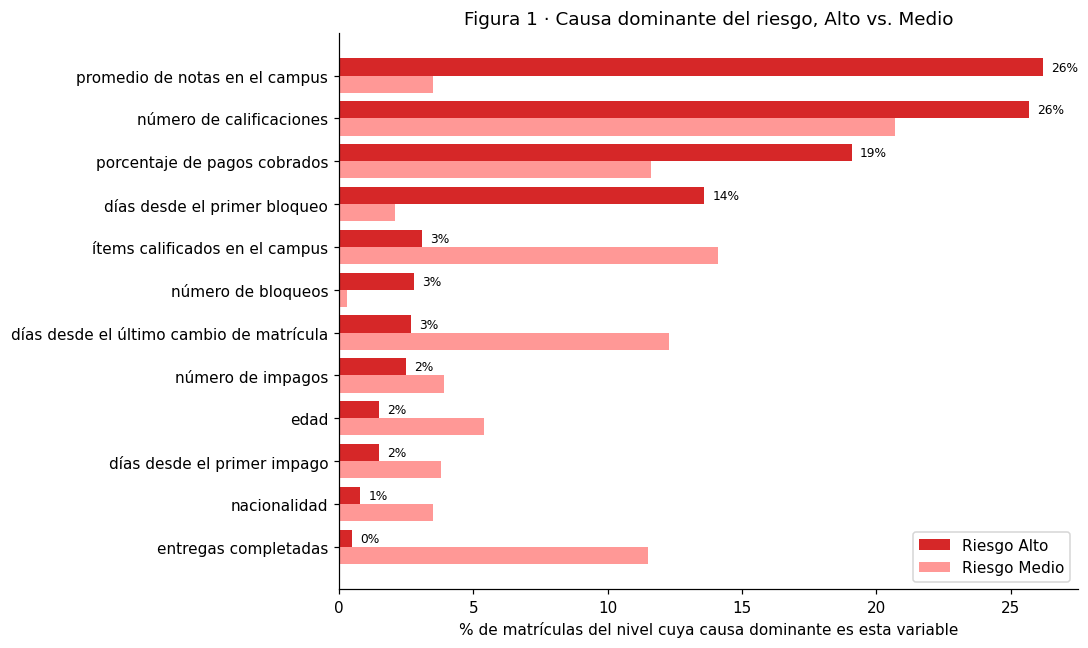

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
top = panorama.head(12).iloc[::-1]
y = np.arange(len(top))
ax.barh(y + 0.2, top["% Alto"], height=0.4, label="Riesgo Alto", color="#d62728")
ax.barh(y - 0.2, top["% Medio"], height=0.4, label="Riesgo Medio", color="#ff9896")
ax.set_yticks(y)
ax.set_yticklabels(top["label"])
ax.set_xlabel("% de matrículas del nivel cuya causa dominante es esta variable")
ax.set_title("Figura 1 · Causa dominante del riesgo, Alto vs. Medio")
ax.legend(loc="lower right")
for yi, (a, m) in enumerate(zip(top["% Alto"], top["% Medio"])):
    ax.text(a + 0.3, yi + 0.2, f"{a:.0f}%", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig01_causa_dominante.png", bbox_inches="tight")
plt.show()

### 3.1 Severidad de la causa dominante y perfil de riesgo

¿La causa dominante describe realmente un comportamiento riesgoso (severidad extrema del
lado malo) o es contexto?

In [8]:
sev_dom = pd.crosstab(dom.nivel, dom.clasificacion, normalize="index").mul(100).round(1)
sev_dom.columns = [f"% dominante {c}" for c in sev_dom.columns]
display(sev_dom)

perfil_tab = pd.crosstab(dom.perfil_grupo, dom.nivel).sort_values("Alto", ascending=False)
perfil_tab["% Alto"] = (perfil_tab["Alto"] / perfil_tab["Alto"].sum() * 100).round(1)
perfil_tab.head(8)

,% dominante eleva,% dominante favorable,% dominante indeterminado
nivel,,,
Alto,80.7,2.3,17.0
Medio,56.0,12.9,31.1


nivel,Alto,Medio,% Alto
perfil_grupo,,,
Academico + Compromiso,348,908,46.5
Contextual + Financiero,95,30,12.7
Compromiso + Contextual,80,242,10.7
Academico + Financiero,79,97,10.6
Academico + Contextual,67,111,9.0
Contextual,41,4,5.5
Academico,24,4,3.2
Compromiso + Financiero,9,82,1.2


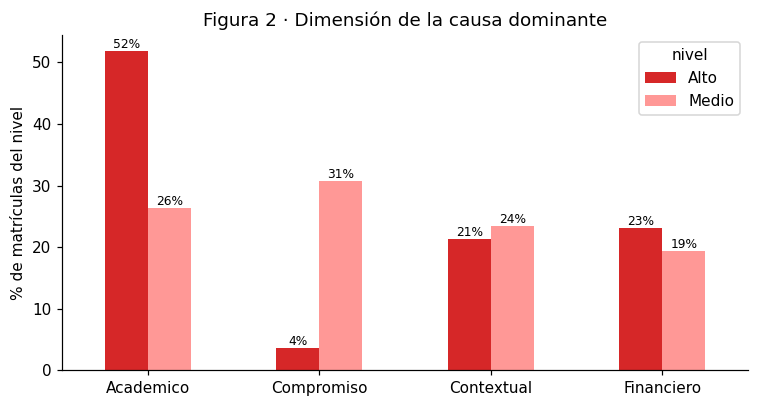

In [9]:
macro_dom = pd.crosstab(dom.macro, dom.nivel, normalize="columns").mul(100).round(1)[NIVELES_ANALISIS]
fig, ax = plt.subplots(figsize=(7, 3.8))
macro_dom.plot(kind="bar", ax=ax, color=["#d62728", "#ff9896"], rot=0)
ax.set_ylabel("% de matrículas del nivel")
ax.set_xlabel("")
ax.set_title("Figura 2 · Dimensión de la causa dominante")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig02_macro_dominante.png", bbox_inches="tight")
plt.show()

## 4. Riesgo relativo por contexto: dónde se concentra el riesgo

Antes de mirar causas, conviene saber **en qué contextos el riesgo Alto está
sobre-representado**. El riesgo relativo (RR) compara la tasa de riesgo Alto del contexto
con la tasa base de toda la población activa.

In [10]:
ctx = (activos.groupby("contexto")[COLS["nivel"]].value_counts().unstack(fill_value=0)
       .reindex(columns=["Alto", "Medio", "Bajo"], fill_value=0))
ctx["activos"] = ctx.sum(axis=1)
ctx["riesgo (A+M)"] = ctx["Alto"] + ctx["Medio"]
ctx["% Alto"] = (ctx["Alto"] / ctx["activos"] * 100).round(1)
ctx["RR Alto"] = (ctx["Alto"] / ctx["activos"] / TASA_BASE_FOCO).round(2)
ctx["% A+M"] = (ctx["riesgo (A+M)"] / ctx["activos"] * 100).round(1)
ctx["RR A+M"] = (ctx["riesgo (A+M)"] / ctx["activos"] / TASA_BASE_RIESGO).round(2)
ctx = ctx.reset_index()
ctx[["titulacion", "tipo_estudiante"]] = ctx.contexto.str.rsplit(" · ", n=1, expand=True)

evaluables = ctx[ctx["activos"] >= 30].copy()
sobre_rep = evaluables[(evaluables["RR Alto"] >= RR_MINIMO) & (evaluables["Alto"] >= MIN_FOCO_CONTEXTO)].sort_values("RR Alto", ascending=False)
sub_rep = evaluables[(evaluables["RR Alto"] <= 1 / RR_MINIMO)].sort_values("RR Alto")

print(f"Contextos con ≥30 activos: {len(evaluables)} de {len(ctx)}")
print(f"Sobre-representados (RR Alto ≥ {RR_MINIMO}, ≥{MIN_FOCO_CONTEXTO} en Alto): {len(sobre_rep)}")
print(f"Sub-representados (RR Alto ≤ {1/RR_MINIMO:.2f}): {len(sub_rep)}")
sobre_rep[["contexto", "activos", "Alto", "Medio", "% Alto", "RR Alto", "% A+M", "RR A+M"]]

Contextos con ≥30 activos: 69 de 103
Sobre-representados (RR Alto ≥ 1.5, ≥10 en Alto): 16
Sub-representados (RR Alto ≤ 0.67): 29


nivel_riesgo_mensual,contexto,activos,Alto,Medio,% Alto,RR Alto,% A+M,RR A+M
28,Grado en Logopedia · Nuevo ingreso,51,23,8,45.1,4.51,60.8,2.03
63,Máster Universitario en Dirección Financiera y Control de Gestión ...,86,34,14,39.5,3.95,55.8,1.86
15,Grado en Economía · Nuevo ingreso,30,11,11,36.7,3.67,73.3,2.44
23,Grado en Ingeniería Informática · Nuevo ingreso,31,10,11,32.3,3.22,67.7,2.26
43,Máster U. en Direcc y Adm de Empresas (MBA)/Master in Business Adm...,191,57,90,29.8,2.98,77.0,2.57
69,Máster Universitario en Dirección y Gestión Pública · Nuevo ingreso,39,11,23,28.2,2.82,87.2,2.91
84,Máster Universitario en Marketing Digital y Redes Sociales · Nuevo...,79,21,24,26.6,2.66,57.0,1.90
25,Grado en Ingeniería de Organización Industrial · Nuevo ingreso,62,16,21,25.8,2.58,59.7,1.99
36,Grado en Psicología · Nuevo ingreso,393,101,126,25.7,2.57,57.8,1.93
73,Máster Universitario en Educación Inclusiva y Personalizada · Nuev...,55,14,0,25.5,2.54,25.5,0.85


In [11]:
# Nuevo ingreso vs. reingreso: la primera lectura de "primer año"
ni = pd.crosstab(activos["tipo_estudiante_label"], activos[COLS["nivel"]]).reindex(columns=["Alto", "Medio", "Bajo"])
ni["activos"] = ni.sum(axis=1)
ni["% Alto"] = (ni["Alto"] / ni["activos"] * 100).round(1)
ni["RR Alto"] = (ni["Alto"] / ni["activos"] / TASA_BASE_FOCO).round(2)
ni

nivel_riesgo_mensual,Alto,Medio,Bajo,activos,% Alto,RR Alto
tipo_estudiante_label,,,,,,
Nuevo ingreso,578,868,1984,3430,16.9,1.68
Reingreso,170,627,3250,4047,4.2,0.42


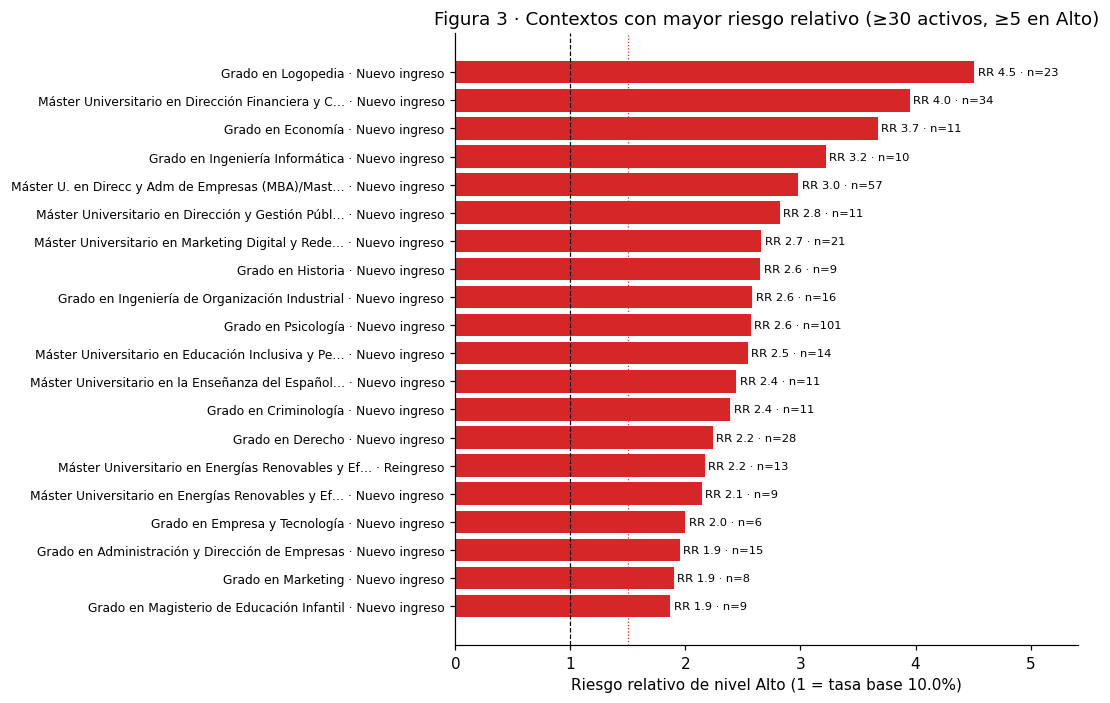

In [12]:
fig, ax = plt.subplots(figsize=(10, 6.5))
plot_ctx = evaluables[evaluables["Alto"] >= 5].sort_values("RR Alto", ascending=True).tail(20)
colors = ["#d62728" if r >= RR_MINIMO else ("#7f7f7f" if r >= 1 else "#2ca02c") for r in plot_ctx["RR Alto"]]
ypos = np.arange(len(plot_ctx))
ax.barh(ypos, plot_ctx["RR Alto"], color=colors)
ax.set_yticks(ypos); ax.set_yticklabels([ctx_corto(c, 48) for c in plot_ctx.contexto], fontsize=8)
ax.axvline(1, color="black", lw=0.8, ls="--")
ax.axvline(RR_MINIMO, color="#d62728", lw=0.8, ls=":")
ax.set_xlabel(f"Riesgo relativo de nivel Alto (1 = tasa base {TASA_BASE_FOCO:.1%})")
ax.set_title("Figura 3 · Contextos con mayor riesgo relativo (≥30 activos, ≥5 en Alto)")
for yi, (rr, n) in enumerate(zip(plot_ctx["RR Alto"], plot_ctx["Alto"])):
    ax.text(rr + 0.03, yi, f"RR {rr:.1f} · n={n}", va="center", fontsize=7.5)
ax.set_xlim(0, plot_ctx["RR Alto"].max() * 1.2)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig03_riesgo_relativo_contexto.png", bbox_inches="tight")
plt.show()

### 4.1 Nuevo ingreso vs. reingreso, Grado vs. Máster: dos mapas de causas distintos

Antes de bajar a la titulación, la lectura por tipo de estudiante y de titulación muestra
si el riesgo Alto tiene la misma naturaleza en toda la población o si cambia de origen.

In [13]:
dom_alto = dom[dom.nivel == NIVEL_FOCO]
por_tipo_est = pd.crosstab(dom_alto.label, dom_alto.tipo_estudiante, normalize="columns").mul(100).round(1)
por_tipo_tit = pd.crosstab(dom_alto.label, dom_alto.tipo_titulacion, normalize="columns").mul(100).round(1)
por_tipo_tit = por_tipo_tit[[c for c in ["Grado", "Máster"] if c in por_tipo_tit.columns]]
mapa_causas = pd.concat([por_tipo_est, por_tipo_tit], axis=1).fillna(0)
mapa_causas["n Alto"] = dom_alto.label.value_counts()
mapa_causas = mapa_causas.sort_values("n Alto", ascending=False)
print(f"% de matrículas de riesgo {NIVEL_FOCO} por causa dominante, dentro de cada columna")
mapa_causas.head(10)

% de matrículas de riesgo Alto por causa dominante, dentro de cada columna


,Nuevo ingreso,Reingreso,Grado,Máster,n Alto
label,,,,,
promedio de notas en el campus,33.0,2.9,40.5,13.8,196
número de calificaciones,31.1,7.1,20.2,30.2,192
porcentaje de pagos cobrados,12.6,41.2,12.4,24.8,143
días desde el primer bloqueo,12.3,18.2,10.1,16.9,102
ítems calificados en el campus,2.9,3.5,3.2,3.1,23
número de bloqueos,2.2,4.7,3.2,2.6,21
días desde el último cambio de matrícula,1.4,7.1,1.2,4.1,20
número de impagos,1.7,5.3,4.3,1.0,19
edad,0.3,5.3,0.9,2.0,11


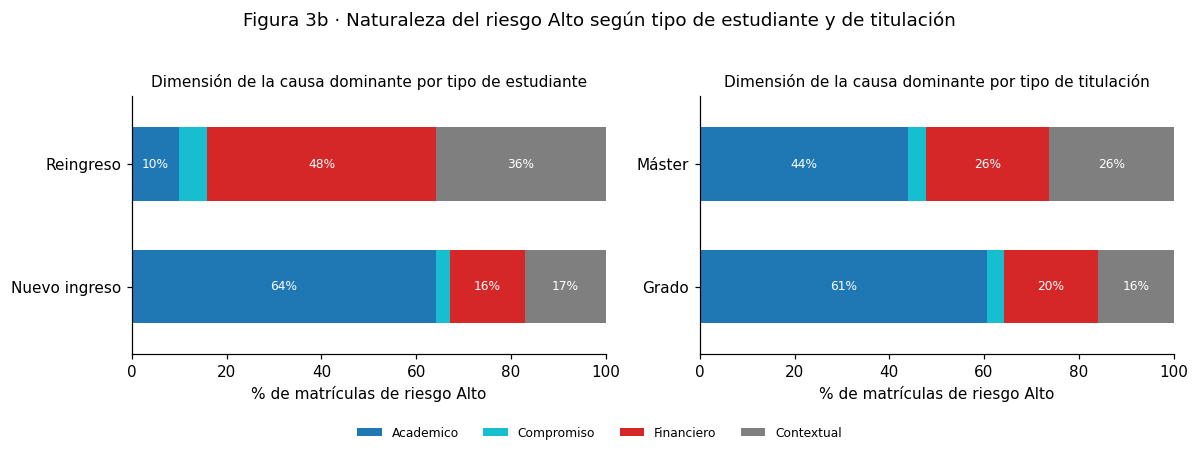

In [14]:
# Dimensión (macro) de la causa dominante, por tipo de estudiante y tipo de titulación
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, titulo in zip(axes, ["tipo_estudiante", "tipo_titulacion"], ["por tipo de estudiante", "por tipo de titulación"]):
    sub = dom_alto if col == "tipo_estudiante" else dom_alto[dom_alto.tipo_titulacion.isin(["Grado", "Máster"])]
    t = pd.crosstab(sub[col], sub.macro, normalize="index").mul(100)
    t = t[[m for m in ["Academico", "Compromiso", "Financiero", "Contextual"] if m in t.columns]]
    t.plot(kind="barh", stacked=True, ax=ax, color=["#1f77b4", "#17becf", "#d62728", "#7f7f7f"], width=0.6, legend=False)
    ax.set_xlabel("% de matrículas de riesgo Alto"); ax.set_ylabel(""); ax.set_title(f"Dimensión de la causa dominante {titulo}", fontsize=10)
    ax.set_xlim(0, 100)
    for i, (idx, row) in enumerate(t.iterrows()):
        acc = 0
        for m, v in row.items():
            if v >= 8:
                ax.text(acc + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white")
            acc += v
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.suptitle("Figura 3b · Naturaleza del riesgo Alto según tipo de estudiante y de titulación", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig03b_macro_por_tipo.png", bbox_inches="tight")
plt.show()

## 5. Nivel 1 · Arquetipos deterministas

Regla de agrupación de referencia (la misma que usa la capa de acción):
**`contexto × perfil_riesgo × hecho dominante`**. Las tres dimensiones ya existen en la
salida del Explicador; no se entrena ni ajusta nada.

Con 96 contextos y tres hechos por matrícula, incluir el perfil fragmenta las cohortes
por debajo del tamaño reportable, y dentro de un `contexto × causa` el perfil es
homogéneo en ~80 % de los casos. Por eso, por defecto (`ARQUETIPO_CON_PERFIL = False`) el
arquetipo es **`contexto × hecho dominante`** y el perfil típico se reporta como atributo
con su grado de homogeneidad. Con el parámetro en `True` se aplica la regla completa.

Para cada arquetipo: volumen total y en Alto, severidad típica y valor mediano de la
causa, si la severidad es graduable, perfil típico y las dos causas secundarias más
frecuentes (posiciones 2 y 3).

In [15]:
def top_secundarias(ids, k=2):
    sec = hechos[(hechos.id.isin(ids)) & (hechos.pos > 1)]
    vc = (sec.label + " [" + sec.severidad + "]").value_counts(normalize=True).head(k)
    return " | ".join(f"{lbl} {p:.0%}" for lbl, p in vc.items())

claves = ["contexto", "perfil_grupo", "fuente"] if ARQUETIPO_CON_PERFIL else ["contexto", "fuente"]
arq_rows = []
for clave, g in dom.groupby(claves):
    n_total = len(g)
    if n_total < MIN_ARQUETIPO:
        continue
    n_alto = int((g.nivel == NIVEL_FOCO).sum())
    arq_rows.append({
        "contexto": g.contexto.iloc[0],
        "causa_dominante": g.label.iloc[0],
        "fuente": g.fuente.iloc[0],
        "dimension": g.dimension.iloc[0],
        "n_total": n_total,
        "n_alto": n_alto,
        "% alto en el arquetipo": round(n_alto / n_total * 100, 1),
        "severidad_tipica": moda(g.severidad),
        "% eleva": round((g.clasificacion == "eleva").mean() * 100, 0),
        "tipo": "severidad no graduable" if g.sin_dispersion_ref.mean() >= 0.5 else "comportamiento",
        "valor_mediano": round(g.valor_num.median(), 2),
        "unidad": moda(g.unidad),
        "perfil_tipico": moda(g.perfil_grupo),
        "homogeneidad_perfil": share_moda(g.perfil_grupo),
        "causas_secundarias": top_secundarias(g.id),
    })
arquetipos = pd.DataFrame(arq_rows).sort_values(["n_alto", "n_total"], ascending=False).reset_index(drop=True)
arquetipos.insert(0, "arquetipo_id", [f"A{i+1:02d}" for i in range(len(arquetipos))])

cobertura_alto = arquetipos.n_alto.sum() / (dom.nivel == NIVEL_FOCO).sum()
cobertura_total = arquetipos.n_total.sum() / len(dom)
print(f"Arquetipos con n ≥ {MIN_ARQUETIPO}: {len(arquetipos)} · cubren el {cobertura_total:.0%} de Alto+Medio y el {cobertura_alto:.0%} de Alto.")
print("El resto queda en grupos demasiado pequeños para reportarse por separado (cola larga de titulaciones); ver vista agregada en 5.1.")
arquetipos.drop(columns=["fuente", "unidad"]).head(20)

Arquetipos con n ≥ 10: 33 · cubren el 37% de Alto+Medio y el 40% de Alto.
El resto queda en grupos demasiado pequeños para reportarse por separado (cola larga de titulaciones); ver vista agregada en 5.1.


,arquetipo_id,contexto,causa_dominante,dimension,n_total,n_alto,% alto en el arquetipo,severidad_tipica,% eleva,tipo,valor_mediano,perfil_tipico,homogeneidad_perfil,causas_secundarias
0,A01,Grado en Psicología · Nuevo ingreso,promedio de notas en el campus,Rendimiento Académico,64,57,89.1,muy bajo,91.0,comportamiento,0.48,Academico + Compromiso,0.80,número de calificaciones [medio] 48% | número de cursos accedidos ...
1,A02,Máster U. en Direcc y Adm de Empresas (MBA)/Master in Business Adm...,número de calificaciones,Rendimiento Académico,34,27,79.4,muy bajo,100.0,comportamiento,0.00,Academico + Compromiso,0.88,días desde el último cambio de matrícula [medio] 28% | días desde ...
2,A03,Máster Universitario en Dirección Financiera y Control de Gestión ...,número de calificaciones,Rendimiento Académico,32,27,84.4,medio,0.0,severidad no graduable,0.00,Academico + Compromiso,0.97,ítems calificados en el campus [bajo] 38% | días desde el último c...
3,A04,Máster U. en Direcc y Adm de Empresas (MBA)/Master in Business Adm...,promedio de notas en el campus,Rendimiento Académico,23,23,100.0,muy bajo,100.0,comportamiento,0.51,Academico + Compromiso,1.00,número de calificaciones [muy bajo] 50% | número de cursos accedid...
4,A05,"Máster Univ en Form. Profesorado de ESO, Bachillerato, FP y Ens. d...",número de calificaciones,Rendimiento Académico,25,21,84.0,muy bajo,100.0,comportamiento,0.00,Academico + Compromiso,0.80,ítems calificados en el campus [muy bajo] 30% | días desde el últi...
5,A06,Grado en Logopedia · Nuevo ingreso,promedio de notas en el campus,Rendimiento Académico,18,18,100.0,muy bajo,100.0,comportamiento,0.50,Academico + Compromiso,0.56,número de calificaciones [medio] 50% | ítems calificados en el cam...
6,A07,Grado en Psicología · Nuevo ingreso,número de calificaciones,Rendimiento Académico,61,17,27.9,medio,3.0,severidad no graduable,0.00,Academico + Compromiso,0.80,días desde el último cambio de matrícula [muy alto] 20% | ítems ca...
7,A08,Máster Universitario en Marketing Digital y Redes Sociales · Nuevo...,número de calificaciones,Rendimiento Académico,20,11,55.0,muy bajo,100.0,comportamiento,0.00,Academico + Compromiso,1.00,días desde el último cambio de matrícula [medio] 28% | ítems calif...
8,A09,Grado en Magisterio de Educación Primaria · Nuevo ingreso,número de calificaciones,Rendimiento Académico,63,10,15.9,muy bajo,100.0,comportamiento,0.00,Academico + Compromiso,0.95,ítems calificados en el campus [bajo] 37% | días desde el último c...
9,A10,Grado en Psicología · Nuevo ingreso,porcentaje de pagos cobrados,Situación Financiera,18,9,50.0,bajo,83.0,comportamiento,72.00,Academico + Financiero,0.56,promedio de notas en el campus [bajo] 17% | promedio de notas en e...


### 5.1 Cola larga: vista agregada por tipo de titulación × tipo de estudiante

La granularidad por titulación deja fuera a la cola larga. Esta vista agrupa por
`tipo_titulacion × tipo_estudiante × causa dominante` y cubre el 100 % de la población,
como red de seguridad para las titulaciones pequeñas.

In [16]:
agg = (dom[dom.tipo_titulacion.isin(["Grado", "Máster"])]
       .groupby(["tipo_titulacion", "tipo_estudiante", "label"]).agg(
           n_total=("id", "size"), n_alto=("nivel", lambda s: int((s == NIVEL_FOCO).sum())),
           severidad_tipica=("severidad", moda), sin_dispersion_ref=("sin_dispersion_ref", "mean"),
           valor_mediano=("valor_num", "median"))
       .reset_index())
agg["% del grupo (A+M)"] = agg.groupby(["tipo_titulacion", "tipo_estudiante"]).n_total.transform(lambda s: s / s.sum() * 100).round(1)
agg["tipo"] = np.where(agg.sin_dispersion_ref >= 0.5, "severidad no graduable", "comportamiento")
agg = agg.drop(columns="sin_dispersion_ref").sort_values(["tipo_titulacion", "tipo_estudiante", "n_alto"], ascending=[True, True, False])
vista_agregada = agg.groupby(["tipo_titulacion", "tipo_estudiante"]).head(3).reset_index(drop=True)
vista_agregada

,tipo_titulacion,tipo_estudiante,label,n_total,n_alto,severidad_tipica,valor_mediano,% del grupo (A+M),tipo
0,Grado,Nuevo ingreso,promedio de notas en el campus,166,136,muy bajo,0.51,22.7,comportamiento
1,Grado,Nuevo ingreso,número de calificaciones,255,66,muy bajo,0.00,34.9,comportamiento
2,Grado,Nuevo ingreso,días desde el primer bloqueo,30,25,medio,137.00,4.1,comportamiento
3,Grado,Reingreso,porcentaje de pagos cobrados,56,18,muy bajo,80.00,15.4,comportamiento
4,Grado,Reingreso,días desde el primer bloqueo,17,10,bajo,153.00,4.7,comportamiento
5,Grado,Reingreso,número de impagos,47,8,muy alto,4.00,12.9,comportamiento
6,Máster,Nuevo ingreso,número de calificaciones,186,110,muy bajo,0.00,26.7,comportamiento
7,Máster,Nuevo ingreso,promedio de notas en el campus,64,53,muy bajo,0.51,9.2,comportamiento
8,Máster,Nuevo ingreso,porcentaje de pagos cobrados,117,46,muy bajo,50.00,16.8,comportamiento
9,Máster,Reingreso,porcentaje de pagos cobrados,93,51,muy bajo,59.00,21.7,comportamiento


## 6. Nivel 1b · Hallazgos sistémicos por concentración

Un **hallazgo sistémico** es un contexto donde una misma causa dominante explica al menos
`UMBRAL_CONCENTRACION` de sus matrículas de riesgo. Cuando eso pasa, el problema deja de
ser individual: es del contexto (onboarding, diseño de la titulación, cobranza, etc.).

Se evalúa en dos capas: sobre **Alto** (foco) y sobre **Alto+Medio** (más volumen, señal
más estable). Dos columnas ayudan a leerlo:
- `lift_vs_global`: concentración del contexto / share global de esa causa. Un share que
  solo replica la distribución general no es un hallazgo del contexto.
- `tipo`: **comportamiento** (la severidad de la causa es graduable y cae del lado que
  eleva el riesgo) o **severidad no graduable** (la referencia del segmento no tiene
  dispersión; el hallazgo se confirma o descarta con las variables crudas del nivel 3).

Una concentración cuya causa cae típicamente del lado **favorable** (p. ej. muchas
entregas) no se declara hallazgo: el modelo la pesó, pero no describe riesgo.

In [17]:
def hallazgos_por_concentracion(dom_df: pd.DataFrame, min_n: int, etiqueta: str) -> pd.DataFrame:
    global_share = dom_df.label.value_counts(normalize=True)
    filas = []
    for ctx_, g in dom_df.groupby("contexto"):
        if len(g) < min_n:
            continue
        vc = g.label.value_counts()
        causa, n_causa = vc.index[0], int(vc.iloc[0])
        share = n_causa / len(g)
        sub = g[g.label == causa]
        vd = g.macro.value_counts(normalize=True)
        filas.append({
            "poblacion": etiqueta,
            "contexto": ctx_,
            "n_riesgo": len(g),
            "n_alto": int((g.nivel == NIVEL_FOCO).sum()),
            "causa_dominante": causa,
            "fuente": moda(sub.fuente),
            "n_causa": n_causa,
            "concentracion": round(share, 3),
            "lift_vs_global": round(share / global_share[causa], 2),
            "severidad_tipica": moda(sub.severidad),
            "% eleva": round((sub.clasificacion == "eleva").mean() * 100, 0),
            "tipo": "severidad no graduable" if sub.sin_dispersion_ref.mean() >= 0.5 else "comportamiento",
            "clasificacion_tipica": moda(sub.clasificacion),
            "valor_mediano": round(sub.valor_num.median(), 2),
            "perfil_tipico": moda(sub.perfil_grupo),
            "dimension_dominante": vd.index[0],
            "concentracion_dimension": round(vd.iloc[0], 3),
            # hallazgo: supera el umbral y la causa no cae típicamente del lado favorable
            "hallazgo": (share >= UMBRAL_CONCENTRACION) and (moda(sub.clasificacion) != "favorable"),
        })
    return pd.DataFrame(filas).sort_values(["hallazgo", "n_causa"], ascending=[False, False]).reset_index(drop=True)

hall_a = hallazgos_por_concentracion(dom[dom.nivel == NIVEL_FOCO], MIN_FOCO_CONTEXTO, "Alto")
hall_am = hallazgos_por_concentracion(dom, MIN_GRUPO_CONTEXTO, "Alto+Medio")
hallazgos = pd.concat([hall_a, hall_am], ignore_index=True)

print(f"Contextos evaluados · Alto: {len(hall_a)} (n ≥ {MIN_FOCO_CONTEXTO}) · Alto+Medio: {len(hall_am)} (n ≥ {MIN_GRUPO_CONTEXTO})")
print(f"Hallazgos sistémicos (concentración ≥ {UMBRAL_CONCENTRACION:.0%}) · Alto: {int(hall_a.hallazgo.sum())} · Alto+Medio: {int(hall_am.hallazgo.sum())}")
cols_h = ["contexto", "n_riesgo", "n_alto", "causa_dominante", "n_causa", "concentracion", "lift_vs_global", "severidad_tipica", "tipo", "valor_mediano", "perfil_tipico", "concentracion_dimension"]
print("\n— Foco: contextos de riesgo ALTO —")
display(hall_a[hall_a.hallazgo][cols_h].drop(columns="n_alto"))
print("\n— Alto + Medio —")
hall_am[hall_am.hallazgo][cols_h]

Contextos evaluados · Alto: 23 (n ≥ 10) · Alto+Medio: 49 (n ≥ 15)
Hallazgos sistémicos (concentración ≥ 40%) · Alto: 15 · Alto+Medio: 19

— Foco: contextos de riesgo ALTO —


,contexto,n_riesgo,causa_dominante,n_causa,concentracion,lift_vs_global,severidad_tipica,tipo,valor_mediano,perfil_tipico,concentracion_dimension
0,Grado en Psicología · Nuevo ingreso,101,promedio de notas en el campus,57,0.564,2.15,muy bajo,comportamiento,0.48,Academico + Compromiso,0.733
1,Máster U. en Direcc y Adm de Empresas (MBA)/Master in Business Adm...,57,número de calificaciones,27,0.474,1.85,muy bajo,comportamiento,0.00,Academico + Compromiso,0.877
2,Máster Universitario en Dirección Financiera y Control de Gestión ...,34,número de calificaciones,27,0.794,3.09,medio,severidad no graduable,0.00,Academico + Compromiso,0.853
3,"Máster Univ en Form. Profesorado de ESO, Bachillerato, FP y Ens. d...",35,número de calificaciones,21,0.600,2.34,muy bajo,comportamiento,0.00,Academico + Compromiso,0.800
4,Grado en Logopedia · Nuevo ingreso,23,promedio de notas en el campus,18,0.783,2.99,muy bajo,comportamiento,0.50,Academico + Compromiso,0.957
5,Máster Universitario en Marketing Digital y Redes Sociales · Nuevo...,21,número de calificaciones,11,0.524,2.04,muy bajo,comportamiento,0.00,Academico + Compromiso,0.905
6,Grado en Magisterio de Educación Primaria · Nuevo ingreso,21,número de calificaciones,10,0.476,1.86,muy bajo,comportamiento,0.00,Academico + Compromiso,0.667
7,Grado en Ingeniería de Organización Industrial · Nuevo ingreso,16,promedio de notas en el campus,8,0.500,1.91,bajo,comportamiento,0.53,Academico + Compromiso,0.750
8,Máster Universitario en Dirección y Gestión Pública · Nuevo ingreso,11,promedio de notas en el campus,8,0.727,2.78,bajo,comportamiento,0.46,Academico + Compromiso,1.000
9,Máster Universitario en Energías Renovables y Eficiencia Energétic...,13,porcentaje de pagos cobrados,7,0.538,2.82,muy bajo,comportamiento,44.00,Academico + Financiero,0.538



— Alto + Medio —


,contexto,n_riesgo,n_alto,causa_dominante,n_causa,concentracion,lift_vs_global,severidad_tipica,tipo,valor_mediano,perfil_tipico,concentracion_dimension
0,Máster U. en Direcc y Adm de Empresas (MBA)/Master in Business Adm...,147,57,días desde el último cambio de matrícula,73,0.497,5.46,bajo,comportamiento,112.00,Academico + Compromiso,0.510
1,Grado en Magisterio de Educación Primaria · Nuevo ingreso,109,21,número de calificaciones,63,0.578,2.59,muy bajo,comportamiento,0.00,Academico + Compromiso,0.651
2,Máster Universitario en Dirección Económico Financiera · Reingreso,78,6,días desde el último cambio de matrícula,55,0.705,7.75,bajo,comportamiento,89.00,Compromiso + Contextual,0.744
3,Máster Universitario en Psicología General Sanitaria · Nuevo ingreso,51,6,porcentaje de pagos cobrados,33,0.647,4.58,muy bajo,comportamiento,50.00,Academico + Compromiso,0.725
4,Máster Universitario en Dirección Financiera y Control de Gestión ...,48,34,número de calificaciones,32,0.667,2.98,medio,severidad no graduable,0.00,Academico + Compromiso,0.729
5,"Máster Univ en Form. Profesorado de ESO, Bachillerato, FP y Ens. d...",56,35,número de calificaciones,25,0.446,2.00,muy bajo,comportamiento,0.00,Academico + Compromiso,0.607
6,Máster Universitario en Dirección y Gestión de Recursos Humanos · ...,34,6,días desde el último cambio de matrícula,24,0.706,7.76,bajo,comportamiento,88.00,Compromiso + Contextual,0.794
7,Máster Universitario en Dirección y Gestión Pública · Nuevo ingreso,34,11,número de calificaciones,23,0.676,3.03,medio,comportamiento,2.00,Academico + Compromiso,0.912
8,Máster Universitario en Marketing Digital y Redes Sociales · Nuevo...,45,21,número de calificaciones,20,0.444,1.99,muy bajo,comportamiento,0.00,Academico + Compromiso,0.622
9,Grado en Logopedia · Nuevo ingreso,31,23,promedio de notas en el campus,18,0.581,5.23,muy bajo,comportamiento,0.50,Academico + Compromiso,0.806


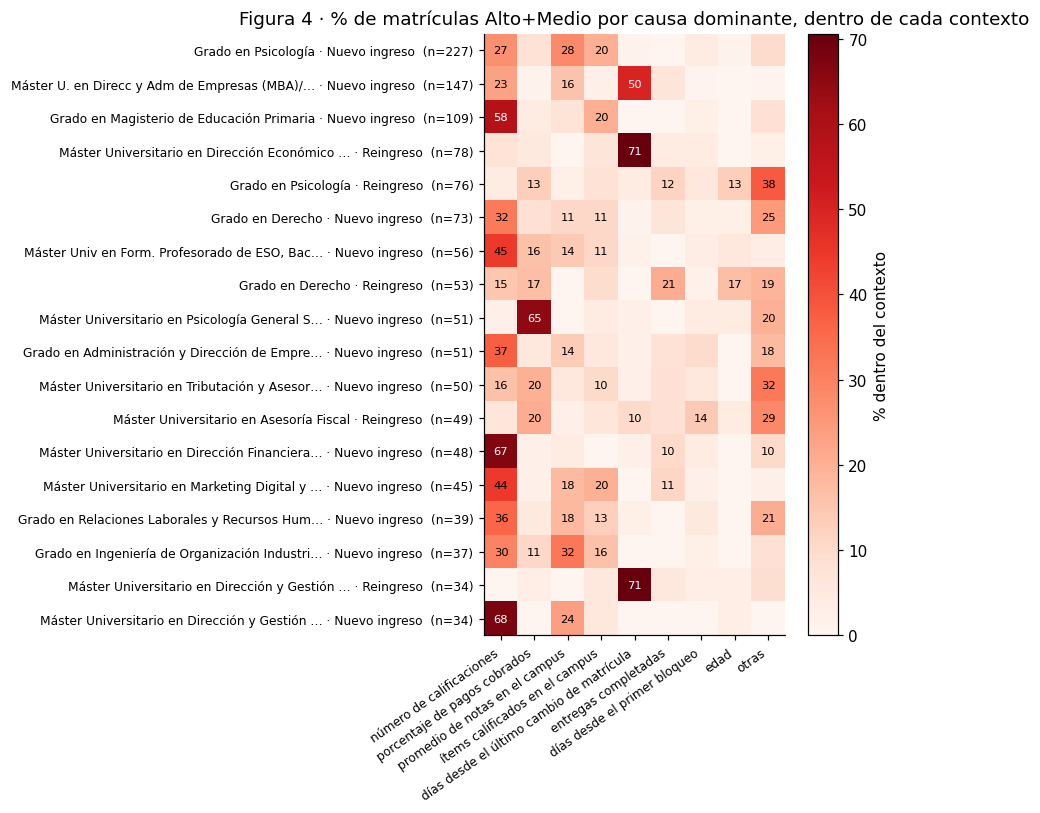

In [18]:
# Mapa de calor: contexto × causa dominante (share dentro del contexto), población Alto+Medio
top_ctx = hall_am.sort_values("n_riesgo", ascending=False).contexto.head(18)
top_causas = dom.label.value_counts().head(8).index
mat = (dom[dom.contexto.isin(top_ctx)]
       .assign(label=lambda d: d.label.where(d.label.isin(top_causas), "otras"))
       .pivot_table(index="contexto", columns="label", values="id", aggfunc="count", fill_value=0))
mat = mat.div(mat.sum(axis=1), axis=0).mul(100)
mat = mat.loc[top_ctx, [c for c in list(top_causas) + ["otras"] if c in mat.columns]]
n_ctx = hall_am.set_index("contexto").n_riesgo

fig, ax = plt.subplots(figsize=(11, 7.5))
im = ax.imshow(mat.values, cmap="Reds", vmin=0, vmax=max(60, mat.values.max()))
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels([f"{ctx_corto(c, 44)}  (n={int(n_ctx[c])})" for c in mat.index], fontsize=8)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if v >= 10:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white" if v > 45 else "black")
ax.set_title("Figura 4 · % de matrículas Alto+Medio por causa dominante, dentro de cada contexto")
plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="% dentro del contexto")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig04_heatmap_contexto_causa.png", bbox_inches="tight")
plt.show()

## 7. Nivel 2 · Co-ocurrencia de hechos

La causa dominante no viene sola: los otros dos hechos del `full_facts` describen el
**cuadro completo**. Acá se buscan pares y tríos de `(variable, severidad)` que aparecen
juntos con frecuencia, y se mide si son más típicos del riesgo Alto que del Medio:

- **soporte**: cuántas matrículas Alto tienen esa combinación entre sus tres hechos.
- **lift Alto vs. Medio**: `% en Alto / % en Medio`, con suavizado (+0,5 en cada conteo)
  para que un 0 en Medio no dé infinito. Un lift de 2 significa que la combinación es el
  doble de frecuente en Alto que en Medio; `exclusivo_Alto` marca las que no aparecen ni
  una vez en Medio. En tablas y gráficos el lift se topea en `LIFT_TOPE_VISUAL`.

Con tres hechos por matrícula el espacio es acotado: todas las combinaciones se enumeran
exhaustivamente, sin heurísticas.

In [19]:
hechos["item"] = hechos.label + " [" + hechos.severidad + "]"
items_por_id = hechos.groupby("id").agg(nivel=("nivel", "first"), contexto=("contexto", "first"),
                                        items=("item", lambda s: tuple(sorted(set(s)))))
N_ALTO = int((items_por_id.nivel == "Alto").sum())
N_MEDIO = int((items_por_id.nivel == "Medio").sum())

def contar_itemsets(tabla: pd.DataFrame, tamanos=(1, 2, 3)) -> pd.DataFrame:
    conteo = {}
    for nivel, its in zip(tabla.nivel, tabla["items"]):
        for k in tamanos:
            for combo in itertools.combinations(its, k):
                d = conteo.setdefault(combo, {"Alto": 0, "Medio": 0})
                d[nivel] += 1
    out = pd.DataFrame([{"items": " + ".join(c), "tamano": len(c), **v} for c, v in conteo.items()])
    out["% Alto"] = (out["Alto"] / N_ALTO * 100).round(1)
    out["% Medio"] = (out["Medio"] / N_MEDIO * 100).round(1)
    out["lift"] = (((out["Alto"] + 0.5) / N_ALTO) / ((out["Medio"] + 0.5) / N_MEDIO)).round(2)
    out["lift_mostrado"] = out["lift"].clip(upper=LIFT_TOPE_VISUAL)
    out["exclusivo_Alto"] = out["Medio"] == 0
    return out

itemsets = contar_itemsets(items_por_id)
combos = itemsets[(itemsets.tamano >= 2) & (itemsets["Alto"] >= MIN_COOCURRENCIA)].copy()
combos_destacados = combos[combos["lift"] >= LIFT_MINIMO].sort_values(["lift", "Alto"], ascending=False)
combos_frecuentes = combos.sort_values("Alto", ascending=False)
cols_c = ["items", "tamano", "Alto", "Medio", "% Alto", "% Medio", "lift_mostrado", "exclusivo_Alto"]

print(f"Combinaciones (pares+tríos) con soporte ≥ {MIN_COOCURRENCIA} en Alto: {len(combos)} · con lift ≥ {LIFT_MINIMO}: {len(combos_destacados)} · exclusivas de Alto: {int(combos.exclusivo_Alto.sum())}")
print("\n— Combinaciones más frecuentes en riesgo Alto —")
display(combos_frecuentes[cols_c].head(12).reset_index(drop=True))
print("\n— Combinaciones más distintivas del riesgo Alto (mayor lift) —")
combos_destacados[cols_c].head(12).reset_index(drop=True)

Combinaciones (pares+tríos) con soporte ≥ 15 en Alto: 41 · con lift ≥ 1.3: 38 · exclusivas de Alto: 4

— Combinaciones más frecuentes en riesgo Alto —


,items,tamano,Alto,Medio,% Alto,% Medio,lift_mostrado,exclusivo_Alto
0,número de calificaciones [muy bajo] + promedio de notas en el camp...,2,112,28,15.0,1.9,7.89,False
1,número de calificaciones [muy bajo] + ítems calificados en el camp...,2,86,48,11.5,3.2,3.56,False
2,días desde el último cambio de matrícula [medio] + número de calif...,2,86,83,11.5,5.6,2.07,False
3,número de calificaciones [muy bajo] + promedio de notas en el camp...,2,62,21,8.3,1.4,5.81,False
4,número de calificaciones [medio] + promedio de notas en el campus ...,2,61,9,8.2,0.6,12.94,False
5,número de calificaciones [medio] + ítems calificados en el campus ...,2,59,22,7.9,1.5,5.29,False
6,días desde el primer bloqueo [bajo] + días desde el último cambio ...,2,50,8,6.7,0.5,11.87,False
7,número de calificaciones [muy bajo] + porcentaje de pagos cobrados...,2,48,23,6.4,1.5,4.12,False
8,días desde el último cambio de matrícula [medio] + porcentaje de p...,2,47,21,6.3,1.4,4.42,False
9,número de calificaciones [muy bajo] + número de cursos accedidos [...,2,42,0,5.6,0.0,20.00,True



— Combinaciones más distintivas del riesgo Alto (mayor lift) —


,items,tamano,Alto,Medio,% Alto,% Medio,lift_mostrado,exclusivo_Alto
0,número de calificaciones [muy bajo] + número de cursos accedidos [...,2,42,0,5.6,0.0,20.00,True
1,número de cursos accedidos [bajo] + promedio de notas en el campus...,2,37,0,4.9,0.0,20.00,True
2,número de calificaciones [muy bajo] + número de cursos accedidos [...,3,37,0,4.9,0.0,20.00,True
3,días desde el primer bloqueo [bajo] + porcentaje de pagos cobrados...,2,17,0,2.3,0.0,20.00,True
4,número de calificaciones [medio] + número de cursos accedidos [medio],2,37,2,4.9,0.1,20.00,False
5,número de calificaciones [medio] + promedio de notas en el campus ...,3,21,1,2.8,0.1,20.00,False
6,número de calificaciones [medio] + número de cursos accedidos [med...,3,25,2,3.3,0.1,20.00,False
7,días desde el primer bloqueo [medio] + porcentaje de pagos cobrado...,2,20,2,2.7,0.1,16.39,False
8,número de calificaciones [medio] + promedio de notas en el campus ...,2,39,5,5.2,0.3,14.35,False
9,número de bloqueos [muy alto] + porcentaje de pagos cobrados [muy ...,2,17,2,2.3,0.1,13.99,False


In [20]:
# Hechos individuales: qué distingue a Alto de Medio, más allá de la causa dominante
singles = itemsets[(itemsets.tamano == 1) & (itemsets["Alto"] >= MIN_COOCURRENCIA)].sort_values("lift", ascending=False)
singles[cols_c].head(12).reset_index(drop=True)

,items,tamano,Alto,Medio,% Alto,% Medio,lift_mostrado,exclusivo_Alto
0,número de cursos accedidos [bajo],1,43,1,5.7,0.1,20.00,False
1,días desde el primer bloqueo [muy bajo],1,18,3,2.4,0.2,10.56,False
2,número de cursos accedidos [medio],1,75,24,10.0,1.6,6.16,False
3,días desde el primer bloqueo [bajo],1,66,22,8.8,1.5,5.91,False
4,número de bloqueos [muy alto],1,34,12,4.5,0.8,5.52,False
5,días desde el primer bloqueo [medio],1,57,24,7.6,1.6,4.69,False
6,promedio de notas en el campus [bajo],1,112,64,15.0,4.3,3.49,False
7,promedio de notas en el campus [muy bajo],1,182,104,24.3,7.0,3.49,False
8,número de bloqueos [medio],1,34,21,4.5,1.4,3.21,False
9,días desde el último cambio de matrícula [alto],1,17,12,2.3,0.8,2.80,False


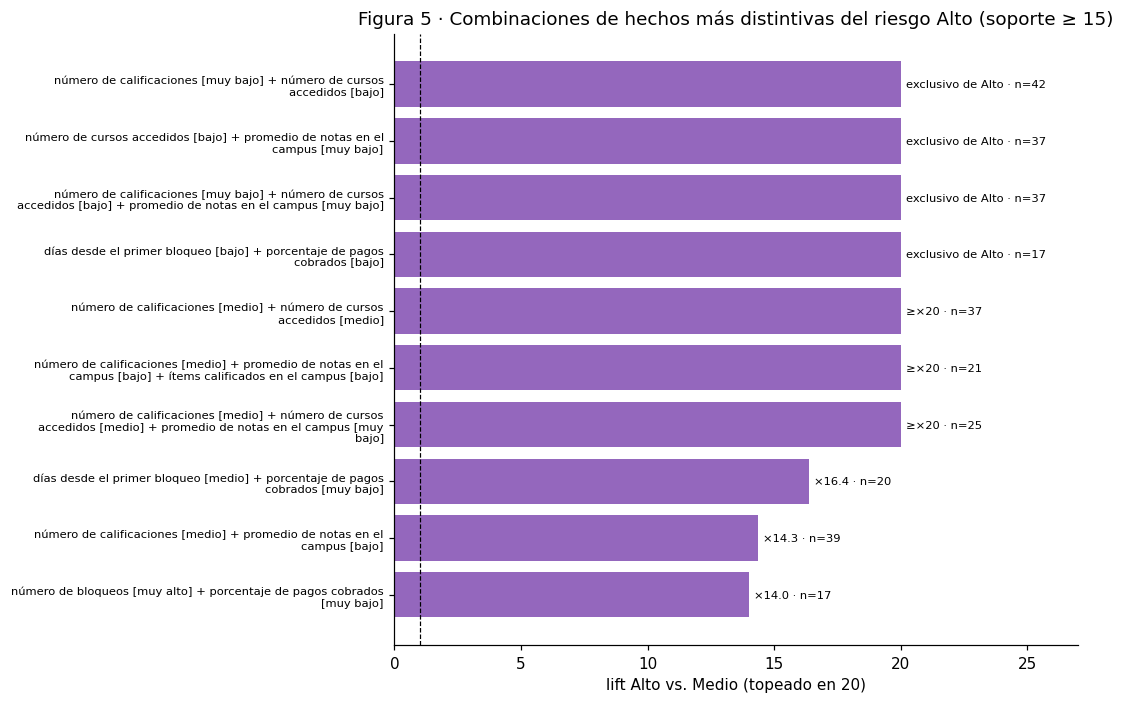

In [21]:
import textwrap
fig, ax = plt.subplots(figsize=(10, 6.5))
plot_c = combos_destacados.head(10).iloc[::-1]
etiquetas = ["\n".join(textwrap.wrap(s, 60)) for s in plot_c["items"]]
ax.barh(etiquetas, plot_c["lift_mostrado"], color="#9467bd")
ax.axvline(1, color="black", lw=0.8, ls="--")
ax.set_xlabel(f"lift Alto vs. Medio (topeado en {LIFT_TOPE_VISUAL})")
ax.set_title(f"Figura 5 · Combinaciones de hechos más distintivas del riesgo Alto (soporte ≥ {MIN_COOCURRENCIA})")
for yi, (l, lm, n, ex) in enumerate(zip(plot_c["lift"], plot_c["lift_mostrado"], plot_c["Alto"], plot_c["exclusivo_Alto"])):
    txt = "exclusivo de Alto" if ex else (f"≥×{LIFT_TOPE_VISUAL}" if l > LIFT_TOPE_VISUAL else f"×{l:.1f}")
    ax.text(lm + 0.2, yi, f"{txt} · n={n}", va="center", fontsize=7.5)
ax.tick_params(axis="y", labelsize=7.5)
ax.set_xlim(0, LIFT_TOPE_VISUAL * 1.35)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig05_coocurrencia_lift.png", bbox_inches="tight")
plt.show()

### 7.1 Dónde vive cada combinación distintiva

Una combinación con lift alto puede estar repartida o concentrarse en pocos contextos. Si
se concentra, es un patrón del contexto; si está repartida, es un patrón transversal.

In [22]:
def contextos_de(combo_str: str, k=3) -> str:
    partes = set(combo_str.split(" + "))
    sub = items_por_id[(items_por_id.nivel == "Alto") & items_por_id["items"].apply(lambda t: partes.issubset(set(t)))]
    vc = sub.contexto.value_counts(normalize=True).head(k)
    return " | ".join(f"{ctx_corto(c)} {p:.0%}" for c, p in vc.items())

donde = combos_destacados.head(10)[["items", "Alto", "lift_mostrado"]].copy()
donde["contextos principales (Alto)"] = donde["items"].map(contextos_de)
donde.reset_index(drop=True)

,items,Alto,lift_mostrado,contextos principales (Alto)
0,número de calificaciones [muy bajo] + número de cursos accedidos [...,42,20.00,Máster U. en Direcc y Adm de Empresas … · Nuevo ingreso 57% | Mást...
1,número de cursos accedidos [bajo] + promedio de notas en el campus...,37,20.00,Máster U. en Direcc y Adm de Empresas … · Nuevo ingreso 65% | Mást...
2,número de calificaciones [muy bajo] + número de cursos accedidos [...,37,20.00,Máster U. en Direcc y Adm de Empresas … · Nuevo ingreso 65% | Mást...
3,días desde el primer bloqueo [bajo] + porcentaje de pagos cobrados...,17,20.00,Máster Universitario en Energías Renov… · Reingreso 18% | Máster U...
4,número de calificaciones [medio] + número de cursos accedidos [medio],37,20.00,Grado en Psicología · Nuevo ingreso 76% | Grado en Logopedia · Nue...
5,número de calificaciones [medio] + promedio de notas en el campus ...,21,20.00,Máster Universitario en Dirección Fina… · Nuevo ingreso 52% | Grad...
6,número de calificaciones [medio] + número de cursos accedidos [med...,25,20.00,Grado en Psicología · Nuevo ingreso 68% | Grado en Logopedia · Nue...
7,días desde el primer bloqueo [medio] + porcentaje de pagos cobrado...,20,16.39,Máster Universitario en Educación Incl… · Nuevo ingreso 25% | Mást...
8,número de calificaciones [medio] + promedio de notas en el campus ...,39,14.35,Grado en Psicología · Nuevo ingreso 67% | Máster Universitario en ...
9,número de bloqueos [muy alto] + porcentaje de pagos cobrados [muy ...,17,13.99,Máster Universitario en Dirección y Ge… · Reingreso 24% | Máster U...


In [23]:
# Cuadro completo de los principales arquetipos: el trío más frecuente
cuadros = []
for _, a in arquetipos.head(8).iterrows():
    ids = dom[(dom.contexto == a.contexto) & (dom.fuente == a.fuente)].id
    sub = items_por_id.loc[items_por_id.index.isin(ids)]
    vc = sub["items"].value_counts()
    cuadros.append({"arquetipo_id": a.arquetipo_id, "contexto": a.contexto, "causa_dominante": a.causa_dominante,
                    "n": len(sub), "trio_mas_frecuente": " + ".join(vc.index[0]), "% del arquetipo": round(vc.iloc[0] / len(sub) * 100, 0)})
pd.DataFrame(cuadros)

,arquetipo_id,contexto,causa_dominante,n,trio_mas_frecuente,% del arquetipo
0,A01,Grado en Psicología · Nuevo ingreso,promedio de notas en el campus,64,número de calificaciones [medio] + número de cursos accedidos [med...,30.0
1,A02,Máster U. en Direcc y Adm de Empresas (MBA)/Master in Business Adm...,número de calificaciones,34,días desde el último cambio de matrícula [medio] + número de calif...,15.0
2,A03,Máster Universitario en Dirección Financiera y Control de Gestión ...,número de calificaciones,32,días desde el último cambio de matrícula [muy alto] + número de ca...,34.0
3,A04,Máster U. en Direcc y Adm de Empresas (MBA)/Master in Business Adm...,promedio de notas en el campus,23,número de calificaciones [muy bajo] + número de cursos accedidos [...,96.0
4,A05,"Máster Univ en Form. Profesorado de ESO, Bachillerato, FP y Ens. d...",número de calificaciones,25,días desde el último cambio de matrícula [medio] + número de calif...,20.0
5,A06,Grado en Logopedia · Nuevo ingreso,promedio de notas en el campus,18,número de calificaciones [medio] + promedio de notas en el campus ...,50.0
6,A07,Grado en Psicología · Nuevo ingreso,número de calificaciones,61,días desde el último cambio de matrícula [muy alto] + días desde l...,13.0
7,A08,Máster Universitario en Marketing Digital y Redes Sociales · Nuevo...,número de calificaciones,20,días desde el último cambio de matrícula [medio] + número de calif...,25.0


## 8. Nivel 3 · Validación con variables crudas

Los hechos del Explicador son relativos al segmento (percentiles) y se limitan al top-3.
Para comprobar que un patrón **discrimina** (y no es solo frecuente), cada grupo se
compara con las matrículas de riesgo **Bajo** sobre las variables crudas disponibles en la
salida.

- Variables numéricas: mediana de cada grupo, test de Mann-Whitney y tamaño del efecto
  como correlación rango-biserial `r` (−1 a 1; |r| ≥ 0,3 moderado, ≥ 0,5 fuerte).
- `sin_avance_registrado`: `pct_avance_aprob` nulo, es decir, la matrícula no tiene
  ninguna calificación registrada. Es la contraparte cruda de «número de calificaciones
  = 0» y se compara como proporción (test z de dos proporciones).

Limitación conocida: `lms_n_entregas_submitted_90d` mira una ventana de 90 días que, en
esta corrida, cae sobre el receso académico; no discrimina niveles y no se usa en la
validación por causa.

In [24]:
activos["sin_avance_registrado"] = activos["pct_avance_aprob"].isna()
base = activos[activos[COLS["nivel"]] == NIVEL_BASE].copy()
activos_idx = activos.set_index(COLS["id"])

RAW_MAP = {
    "lms_nota_media_acum": ["sin_avance_registrado"],
    "n_calificaciones_acum": ["sin_avance_registrado"],
    "lms_n_items_calificados_acum": ["sin_avance_registrado"],
    "lms_n_entregas_submitted_acum": ["sin_avance_registrado"],
    "lms_n_cursos_accedidos_acum": ["sin_avance_registrado"],
    "ratio_cobrado_acum": ["pct_pago_real", "n_impagos_acum"],
    "n_impagos_acum": ["n_impagos_acum", "pct_pago_real"],
    "dias_desde_primer_impago": ["n_impagos_acum", "pct_pago_real"],
    "dias_desde_primer_bloqueo": ["pct_pago_real", "n_impagos_acum"],
    "n_bloqueos_acum": ["pct_pago_real", "n_impagos_acum"],
    "dias_desde_ultimo_cambio_mat": ["n_cambios_mat_acum"],
    "n_cambios_mat_acum": ["n_cambios_mat_acum"],
    "edad_en_observacion": ["edad"],
}

def comparar(grupo: pd.DataFrame, control: pd.DataFrame, col: str) -> dict:
    base_row = {"variable_cruda": col, "n_grupo": int(grupo[col].notna().sum()), "n_control": int(control[col].notna().sum())}
    if col == "sin_avance_registrado":
        a, b = grupo[col].astype(bool), control[col].astype(bool)
        if len(a) < 5 or len(b) < 5:
            return {**base_row, "grupo": np.nan, "control": np.nan, "efecto": np.nan, "p_valor": np.nan}
        pa, pb = a.mean(), b.mean()
        p_pool = (a.sum() + b.sum()) / (len(a) + len(b))
        se = np.sqrt(p_pool * (1 - p_pool) * (1 / len(a) + 1 / len(b))) or np.nan
        z = (pa - pb) / se
        p = 2 * (1 - stats.norm.cdf(abs(z)))
        return {**base_row, "grupo": f"{pa:.0%} sin avance", "control": f"{pb:.0%} sin avance",
                "efecto": f"+{(pa - pb) * 100:.0f} pp", "p_valor": float(f"{p:.2e}")}
    a, b = grupo[col].dropna(), control[col].dropna()
    if len(a) < 5 or len(b) < 5:
        return {**base_row, "grupo": np.nan, "control": np.nan, "efecto": np.nan, "p_valor": np.nan}
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1
    return {**base_row, "grupo": f"mediana {a.median():.2f}", "control": f"mediana {b.median():.2f}",
            "efecto": f"r = {r:+.2f}", "p_valor": float(f"{p:.2e}")}

# 8.1 · Validación global: cada causa dominante (Alto) vs. todos los Bajo
val_global = []
for fuente, g in dom_alto.groupby("fuente"):
    if len(g) < MIN_ARQUETIPO or fuente not in RAW_MAP:
        continue
    grupo = activos_idx.loc[g.id]
    for col in RAW_MAP[fuente]:
        val_global.append({"causa_dominante": g.label.iloc[0], "n_causa": len(g), **comparar(grupo, base, col)})
val_global = pd.DataFrame(val_global).sort_values(["n_causa", "variable_cruda"], ascending=[False, True]).reset_index(drop=True)
print(f"Grupo = matrículas Alto con esa causa dominante · Control = todas las matrículas Bajo ({len(base):,})")
val_global

Grupo = matrículas Alto con esa causa dominante · Control = todas las matrículas Bajo (5,234)


,causa_dominante,n_causa,variable_cruda,n_grupo,n_control,grupo,control,efecto,p_valor
0,promedio de notas en el campus,196,sin_avance_registrado,196,5234,97% sin avance,0% sin avance,+97 pp,0.000000e+00
1,número de calificaciones,192,sin_avance_registrado,192,5234,86% sin avance,0% sin avance,+86 pp,0.000000e+00
2,porcentaje de pagos cobrados,143,n_impagos_acum,143,5234,mediana 0.00,mediana 0.00,r = +0.23,1.990000e-22
3,porcentaje de pagos cobrados,143,pct_pago_real,143,4938,mediana 0.55,mediana 1.00,r = -0.87,2.620000e-85
4,días desde el primer bloqueo,102,n_impagos_acum,102,5234,mediana 0.00,mediana 0.00,r = +0.21,1.590000e-14
5,días desde el primer bloqueo,102,pct_pago_real,100,4938,mediana 0.75,mediana 1.00,r = -0.72,1.320000e-41
6,ítems calificados en el campus,23,sin_avance_registrado,23,5234,61% sin avance,0% sin avance,+61 pp,0.000000e+00
7,número de bloqueos,21,n_impagos_acum,21,5234,mediana 0.00,mediana 0.00,r = +0.02,7.120000e-01
8,número de bloqueos,21,pct_pago_real,17,4938,mediana 0.80,mediana 1.00,r = -0.70,4.170000e-08
9,días desde el último cambio de matrícula,20,n_cambios_mat_acum,20,5234,mediana 6.00,mediana 5.00,r = +0.13,3.070000e-01


In [25]:
# 8.2 · Validación por hallazgo sistémico (Alto): el grupo vs. los Bajo del mismo contexto
val_hall = []
for _, h in hall_a[hall_a.hallazgo].iterrows():
    ids = dom[(dom.contexto == h.contexto) & (dom.nivel == NIVEL_FOCO) & (dom.fuente == h.fuente)].id
    grupo = activos_idx.loc[ids]
    control = base[base.contexto == h.contexto]
    for col in RAW_MAP.get(h.fuente, []):
        val_hall.append({"contexto": h.contexto, "causa_dominante": h.causa_dominante, **comparar(grupo, control, col)})
val_hall = pd.DataFrame(val_hall)
print("Grupo = matrículas Alto del contexto con la causa del hallazgo · Control = matrículas Bajo del mismo contexto")
val_hall

Grupo = matrículas Alto del contexto con la causa del hallazgo · Control = matrículas Bajo del mismo contexto


,contexto,causa_dominante,variable_cruda,n_grupo,n_control,grupo,control,efecto,p_valor
0,Grado en Psicología · Nuevo ingreso,promedio de notas en el campus,sin_avance_registrado,57,166,98% sin avance,1% sin avance,+97 pp,0.000000e+00
1,Máster U. en Direcc y Adm de Empresas (MBA)/Master in Business Adm...,número de calificaciones,sin_avance_registrado,27,44,96% sin avance,0% sin avance,+96 pp,2.220000e-16
2,Máster Universitario en Dirección Financiera y Control de Gestión ...,número de calificaciones,sin_avance_registrado,27,38,96% sin avance,0% sin avance,+96 pp,5.770000e-15
3,"Máster Univ en Form. Profesorado de ESO, Bachillerato, FP y Ens. d...",número de calificaciones,sin_avance_registrado,21,338,95% sin avance,0% sin avance,+95 pp,0.000000e+00
4,Grado en Logopedia · Nuevo ingreso,promedio de notas en el campus,sin_avance_registrado,18,20,100% sin avance,0% sin avance,+100 pp,7.070000e-10
5,Máster Universitario en Marketing Digital y Redes Sociales · Nuevo...,número de calificaciones,sin_avance_registrado,11,34,91% sin avance,0% sin avance,+91 pp,2.900000e-10
6,Grado en Magisterio de Educación Primaria · Nuevo ingreso,número de calificaciones,sin_avance_registrado,10,134,90% sin avance,1% sin avance,+89 pp,0.000000e+00
7,Grado en Ingeniería de Organización Industrial · Nuevo ingreso,promedio de notas en el campus,sin_avance_registrado,8,25,100% sin avance,4% sin avance,+96 pp,1.120000e-07
8,Máster Universitario en Dirección y Gestión Pública · Nuevo ingreso,promedio de notas en el campus,sin_avance_registrado,8,5,100% sin avance,0% sin avance,+100 pp,3.110000e-04
9,Máster Universitario en Energías Renovables y Eficiencia Energétic...,porcentaje de pagos cobrados,pct_pago_real,7,31,mediana 0.44,mediana 1.00,r = -0.94,5.610000e-06


In [26]:
# 8.3 · Lectura rápida: variables crudas por nivel de riesgo (toda la población activa)
por_nivel = activos.groupby(COLS["nivel"])[RAW_COLS].median().T.reindex(columns=["Alto", "Medio", "Bajo"]).round(2)
por_nivel.loc["% sin avance registrado"] = activos.groupby(COLS["nivel"])["sin_avance_registrado"].mean().mul(100).round(1).reindex(["Alto", "Medio", "Bajo"]).values
por_nivel.loc["% sin entregas LMS 90d"] = activos.groupby(COLS["nivel"])["lms_n_entregas_submitted_90d"].apply(lambda s: round((s == 0).mean() * 100, 1)).reindex(["Alto", "Medio", "Bajo"]).values
por_nivel.loc["% con algún impago"] = activos.groupby(COLS["nivel"])["n_impagos_acum"].apply(lambda s: round((s > 0).mean() * 100, 1)).reindex(["Alto", "Medio", "Bajo"]).values
print("Mediana de cada variable cruda por nivel; las tres últimas filas son porcentajes de matrículas")
por_nivel

Mediana de cada variable cruda por nivel; las tres últimas filas son porcentajes de matrículas


nivel_riesgo_mensual,Alto,Medio,Bajo
weeks_since_enrollment,36.00,59.00,88.00
asignaturas_matriculadas_acum,1.00,1.00,1.00
pct_avance_aprob,0.40,0.63,0.88
pct_pago_real,0.67,0.91,1.00
monto_pendiente,0.00,0.00,0.00
n_periodos_matriculado,1.00,1.00,2.00
lms_n_entregas_submitted_90d,0.00,0.00,0.00
edad,33.00,33.00,32.00
n_cambios_mat_acum,4.50,5.00,5.00
n_impagos_acum,0.00,0.00,0.00


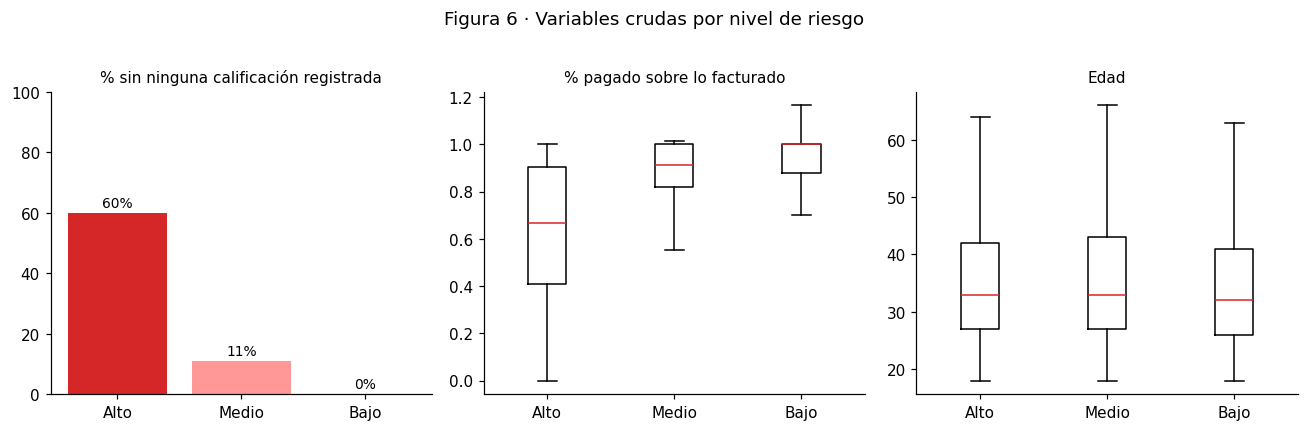

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
niveles = ["Alto", "Medio", "Bajo"]
pcts = [activos.loc[activos[COLS["nivel"]] == n, "sin_avance_registrado"].mean() * 100 for n in niveles]
axes[0].bar(niveles, pcts, color=["#d62728", "#ff9896", "#2ca02c"])
axes[0].set_title("% sin ninguna calificación registrada", fontsize=10); axes[0].set_ylim(0, 100)
for i, v in enumerate(pcts):
    axes[0].text(i, v + 2, f"{v:.0f}%", ha="center", fontsize=9)
for ax, col, titulo in zip(axes[1:], ["pct_pago_real", "edad"], ["% pagado sobre lo facturado", "Edad"]):
    datos = [activos.loc[activos[COLS["nivel"]] == n, col].dropna() for n in niveles]
    ax.boxplot(datos, tick_labels=niveles, showfliers=False, medianprops={"color": "#d62728"})
    ax.set_title(titulo, fontsize=10)
fig.suptitle("Figura 6 · Variables crudas por nivel de riesgo", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig06_crudos_por_nivel.png", bbox_inches="tight")
plt.show()

## 9. Exportación y resumen automático

Todas las tablas se exportan sin identificadores individuales. El resumen automático es un
borrador con los números clave, pensado para alimentar el informe y para comparar corridas.

In [28]:
exports = {
    "panorama_causas_dominantes.csv": panorama,
    "mapa_causas_por_tipo.csv": mapa_causas.reset_index(),
    "riesgo_por_contexto.csv": ctx.sort_values("Alto", ascending=False),
    "arquetipos.csv": arquetipos,
    "vista_agregada.csv": vista_agregada,
    "hallazgos_sistemicos.csv": hallazgos,
    "coocurrencias.csv": combos.sort_values("Alto", ascending=False),
    "coocurrencias_donde.csv": donde,
    "validacion_crudos_global.csv": val_global,
    "validacion_crudos_hallazgos.csv": val_hall,
    "crudos_por_nivel.csv": por_nivel.reset_index().rename(columns={"index": "variable"}),
    "control_diccionario.csv": control_dicc.reset_index().rename(columns={"index": "fuente"}),
}
for nombre, tabla in exports.items():
    tabla.to_csv(TAB_DIR / nombre, index=False, encoding="utf-8")
print("Tablas exportadas:", ", ".join(exports))

Tablas exportadas: panorama_causas_dominantes.csv, mapa_causas_por_tipo.csv, riesgo_por_contexto.csv, arquetipos.csv, vista_agregada.csv, hallazgos_sistemicos.csv, coocurrencias.csv, coocurrencias_donde.csv, validacion_crudos_global.csv, validacion_crudos_hallazgos.csv, crudos_por_nivel.csv, control_diccionario.csv


In [29]:
n_alto_total = int((activos[COLS["nivel"]] == "Alto").sum())
lineas = [
    "# Resumen automático · patrones de riesgo\n",
    f"- Población: {len(activos):,} activas · Alto {n_alto_total:,} ({TASA_BASE_FOCO:.1%}) · Medio {int((activos[COLS['nivel']]=='Medio').sum()):,} · Bajo {len(base):,}",
    f"- Causas dominantes en Alto: las 4 primeras concentran el {panorama['% Alto acumulado'].iloc[3]:.0f}%: "
    + "; ".join(f"{r.label} ({r['% Alto']:.0f}%)" for _, r in panorama.head(4).iterrows()),
    f"- Causa dominante que eleva el riesgo (severidad del lado malo): {sev_dom.loc['Alto', '% dominante eleva']:.0f}% en Alto, {sev_dom.loc['Medio', '% dominante eleva']:.0f}% en Medio",
    f"- Nuevo ingreso: RR Alto = {ni.loc['Nuevo ingreso', 'RR Alto']:.2f} · Reingreso: RR Alto = {ni.loc['Reingreso', 'RR Alto']:.2f}",
    f"- Contextos sobre-representados (RR ≥ {RR_MINIMO}, ≥{MIN_FOCO_CONTEXTO} Alto): {len(sobre_rep)} → "
    + "; ".join(f"{r.contexto} (RR {r['RR Alto']:.1f}, n={r.Alto})" for _, r in sobre_rep.head(6).iterrows()),
    f"- Arquetipos (n ≥ {MIN_ARQUETIPO}): {len(arquetipos)} · cubren {cobertura_alto:.0%} de Alto",
    f"- Hallazgos sistémicos Alto (≥ {UMBRAL_CONCENTRACION:.0%}): {int(hall_a.hallazgo.sum())} de {len(hall_a)} contextos evaluados · de ellos, con severidad no graduable: {int((hall_a.hallazgo & (hall_a.tipo == 'severidad no graduable')).sum())}",
    f"- Hallazgos sistémicos Alto+Medio: {int(hall_am.hallazgo.sum())} de {len(hall_am)} contextos evaluados",
    f"- Combinaciones distintivas (lift ≥ {LIFT_MINIMO}, soporte ≥ {MIN_COOCURRENCIA}): {len(combos_destacados)} · exclusivas de Alto: {int(combos.exclusivo_Alto.sum())}",
    f"- Sin avance registrado: Alto {por_nivel.loc['% sin avance registrado', 'Alto']:.0f}% · Medio {por_nivel.loc['% sin avance registrado', 'Medio']:.0f}% · Bajo {por_nivel.loc['% sin avance registrado', 'Bajo']:.1f}%",
    f"- Variables con dirección distinta entre output y diccionario: {len(discrepancias)}",
    "\n## Hallazgos sistémicos (Alto)\n",
]
for _, h in hall_a[hall_a.hallazgo].iterrows():
    lineas.append(f"- **{h.contexto}** · n={h.n_riesgo} · {h.concentracion:.0%} comparte «{h.causa_dominante}» [{h.severidad_tipica}] · {h.tipo} · lift vs. global {h.lift_vs_global}")
lineas.append("\n## Arquetipos principales\n")
for _, a in arquetipos.head(10).iterrows():
    lineas.append(f"- {a.arquetipo_id} · {a.contexto} · «{a.causa_dominante}» [{a.severidad_tipica}] · {a.tipo} · n={a.n_total} (Alto {a.n_alto}) · perfil {a.perfil_tipico} ({a.homogeneidad_perfil:.0%})")
lineas.append("\n## Combinaciones distintivas\n")
for _, c in combos_destacados.head(8).iterrows():
    lift_txt = "exclusivo de Alto" if c.exclusivo_Alto else f"lift ×{c.lift:.1f}"
    lineas.append(f"- {c['items']} · n Alto={c.Alto} ({c['% Alto']}%) · {lift_txt}")
(OUT_DIR / "resumen_automatico.md").write_text("\n".join(lineas), encoding="utf-8")
print("\n".join(lineas))

# Resumen automático · patrones de riesgo

- Población: 7,477 activas · Alto 748 (10.0%) · Medio 1,495 · Bajo 5,234
- Causas dominantes en Alto: las 4 primeras concentran el 85%: promedio de notas en el campus (26%); número de calificaciones (26%); porcentaje de pagos cobrados (19%); días desde el primer bloqueo (14%)
- Causa dominante que eleva el riesgo (severidad del lado malo): 81% en Alto, 56% en Medio
- Nuevo ingreso: RR Alto = 1.68 · Reingreso: RR Alto = 0.42
- Contextos sobre-representados (RR ≥ 1.5, ≥10 Alto): 16 → Grado en Logopedia · Nuevo ingreso (RR 4.5, n=23); Máster Universitario en Dirección Financiera y Control de Gestión · Nuevo ingreso (RR 4.0, n=34); Grado en Economía · Nuevo ingreso (RR 3.7, n=11); Grado en Ingeniería Informática · Nuevo ingreso (RR 3.2, n=10); Máster U. en Direcc y Adm de Empresas (MBA)/Master in Business Admin. (MBA) · Nuevo ingreso (RR 3.0, n=57); Máster Universitario en Dirección y Gestión Pública · Nuevo ingreso (RR 2.8, n=11)
- Arquetipos (n 